# R1: Raw audit

**Goal:** look at the four raw files exactly as we got them, and write down every problem with numbers.
Nothing is changed here. The fixing happens in R2 to R4, and every fix points back to a number from this notebook.

**Rule:** never print rows of the raw data. They contain farmer names and phone numbers.
We only print column names, counts and summaries.

**All outputs go to** `results/phase1a/`.

## Setup

Loads the tools, finds the project folders, and opens the four raw shapefiles without changing them.
Also defines a few small helpers used later.

In [2]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy import stats

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
RAW = ROOT / "data" / "raw"
OUT = ROOT / "results" / "phase1a"
OUT.mkdir(parents=True, exist_ok=True)

YEARS = [2022, 2023, 2024, 2025]
raw = {y: gpd.read_file(RAW / f"Latur_GT_ND_{y}.shp") for y in YEARS}

PERSONAL = ["Farmer", "Phone", "Agent", "AgentPhone", "Farm", "Survey_No", "Survey No"]
NA_WORDS = {"", "-", "--", "n/a", "na", "nan", "none", "null"}
ACRE = 4046.8564224    # square metres in one acre

def is_filled(s):
    """True where a value is really there (not empty, '-', 'N/A' and so on)."""
    return s.notna() & ~s.astype(str).str.strip().str.lower().isin(NA_WORDS)

def farmer_code(g):
    """Anonymous code per farmer (name + phone), so we can compare farmers without seeing them."""
    key = (g["Farmer"].astype(str).str.strip().str.lower() + "|" +
           g["Phone"].astype(str).str.strip())
    return key.apply(lambda s: hashlib.sha1(s.encode()).hexdigest()[:10])

print("Loaded:", {y: len(g) for y, g in raw.items()}, "fields")

Loaded: {2022: 55, 2023: 60, 2024: 323, 2025: 769} fields


## Step 1: What did we get?

One summary row per year: coordinate system, shape type, number of fields and columns, missing polygons.
Then the column names of each year.

**Found:** 1,207 fields (55, 60, 323, 769), all in EPSG:4326. 2022 to 2024 have 46 columns
(two survey batches merged), 2025 has 27. One 2025 field has no polygon.

In [3]:
summary = pd.DataFrame([{
    "year": y,
    "crs": str(g.crs),
    "shape_types": ", ".join(sorted(g.geom_type.dropna().unique())),
    "fields": len(g),
    "columns": g.shape[1] - 1,
    "missing_polygon": int(g.geometry.isna().sum()),
    "empty_polygon": int(g.geometry.is_empty.fillna(False).sum()),
} for y, g in raw.items()])
summary.to_csv(OUT / "R1_file_summary.csv", index=False)
print(summary.to_string(index=False))

for y, g in raw.items():
    cols = list(g.drop(columns="geometry").columns)
    print(f"\n{y}: {len(cols)} columns")
    print(cols)

 year       crs           shape_types  fields  columns  missing_polygon  empty_polygon
 2022 EPSG:4326               Polygon      55       46                0              0
 2023 EPSG:4326 MultiPolygon, Polygon      60       46                0              0
 2024 EPSG:4326 MultiPolygon, Polygon     323       46                0              0
 2025 EPSG:4326               Polygon     769       27                1              0

2022: 46 columns
['fid', 'UID', 'Farm', 'Farmer', 'Phone', 'Survey_No', 'State', 'District', 'Taluka', 'Village', 'SColor', 'SStructure', 'STexture', 'SDepth', 'Carbon', 'pH', 'EC', 'Nitrogen', 'Phosphorus', 'Potassium', 'Crop_Name', 'Irrigation', 'A_Variety', 'C_Yeild', 'HA_Date', 'ASowing', 'Area_acres', 'Survey No', 'Copper', 'Iron', 'Manganese', 'Zinc', 'Water pH', 'Water EC', 'Na Ratio', 'Boron', 'Crop Name', 'PSowing', 'PArea', 'Expected', 'AArea', 'Agent', 'AgentPhone', 'PolyArea', 'layer', 'path']

2023: 46 columns
['fid', 'UID', 'Farm', 'Farmer', 'P

## Step 2: How full is each column?

For every column and year we count real values and every kind of placeholder
(blank, "-", "N/A", -99, zero). Personal columns are counted, but their values are hidden.

**Found:** the two batches fill different columns and never overlap. Soil lab values look full in
2022 to 2024, but many are zeros; only 232 fields have real values (Step 6D). `Expected` is a form
default. Variety names are messy.

In [4]:
NA_TEXT = {"n/a", "na", "nan", "none", "null"}

def profile(s, personal):
    n = len(s)
    st = s.astype(str).str.strip()
    notnull = s.notna()
    num = pd.to_numeric(s, errors="coerce")
    row = {
        "dtype": str(s.dtype), "n": n,
        "null": int((~notnull).sum()),
        "blank": int((notnull & (st == "")).sum()),
        "dash": int((notnull & st.isin(["-", "--"])).sum()),
        "na_text": int((notnull & st.str.lower().isin(NA_TEXT)).sum()),
        "minus99": int((num == -99).sum()),
        "zero": int((num == 0).sum()),
        "n_unique": int(s[notnull].nunique()),
    }
    bad = row["null"] + row["blank"] + row["dash"] + row["na_text"] + row["minus99"]
    row["usable_pct"] = round(100 * (n - bad) / n, 1)
    numeric_share = num.notna().sum() / max(notnull.sum(), 1)
    row["numeric_share"] = round(numeric_share, 2)
    if personal:
        row["summary"] = "(personal: values hidden)"
    elif numeric_share > 0.9:
        v = num[(num != -99) & num.notna()]
        row["summary"] = f"min {v.min():.3g} | median {v.median():.3g} | max {v.max():.3g}" if len(v) else ""
    else:
        top = st[notnull].value_counts().head(5)
        row["summary"] = "; ".join(f"{k} ({c})" for k, c in top.items())
    return row

rows = []
for y, g in raw.items():
    for col in g.drop(columns="geometry").columns:
        r = profile(g[col], col in PERSONAL)
        r.update({"year": y, "column": col})
        rows.append(r)

prof = pd.DataFrame(rows)[["year", "column", "dtype", "n", "null", "blank", "dash", "na_text",
                           "minus99", "zero", "n_unique", "usable_pct", "numeric_share", "summary"]]
prof.to_csv(OUT / "R1_column_profile.csv", index=False)

usable = prof.pivot(index="column", columns="year", values="usable_pct")
order = list(raw[2022].drop(columns="geometry").columns)
usable = usable.reindex(order + [c for c in usable.index if c not in order])
print("Percent of real values per column and year")
print(usable.to_string())

Percent of real values per column and year
year         2022   2023   2024   2025
column                                
fid         100.0  100.0  100.0    NaN
UID         100.0  100.0  100.0  100.0
Farm        100.0  100.0  100.0  100.0
Farmer      100.0  100.0  100.0  100.0
Phone       100.0  100.0  100.0  100.0
Survey_No    40.0   20.0    7.1   98.3
State       100.0  100.0  100.0  100.0
District    100.0  100.0  100.0  100.0
Taluka      100.0  100.0  100.0  100.0
Village     100.0  100.0  100.0  100.0
SColor       47.3  100.0   36.8  100.0
SStructure   47.3  100.0   36.8  100.0
STexture     47.3  100.0   36.8  100.0
SDepth       47.3  100.0   36.8  100.0
Carbon      100.0  100.0  100.0    1.3
pH          100.0  100.0  100.0    1.3
EC          100.0  100.0  100.0    1.3
Nitrogen    100.0  100.0  100.0    1.3
Phosphorus  100.0  100.0  100.0    1.3
Potassium   100.0  100.0  100.0    1.3
Crop_Name    40.0   20.0    7.1  100.0
Irrigation  100.0  100.0  100.0  100.0
A_Variety    69.1  10

## Step 3: Duplicates, overlaps, multi-part fields and farmers

Counts duplicate IDs and identical polygons, fields drawn in several pieces, broken polygons,
fields that overlap in the same year, and how many fields each farmer has (anonymous code).
Overlap is measured as IoU = shared area / combined area. Above 0.9 means probably the same field twice.

**Found:** no duplicate IDs. 6 multi-part fields, 2 broken polygons (2025).
In 2025, 8 pairs of fields overlap by more than half. 64 farmers have more than one field in a year.

In [5]:
rows = []
for y, g in raw.items():
    r = {"year": y, "fields": len(g)}
    geo = g.geometry.dropna()
    r["duplicate_ids"] = int(g["UID"].duplicated().sum())
    r["identical_polygons"] = int(geo.to_wkb().duplicated().sum())
    multi = geo[geo.geom_type == "MultiPolygon"]
    r["multi_part_fields"] = len(multi)
    r["max_parts"] = int(multi.apply(lambda m: len(m.geoms)).max()) if len(multi) else 0
    r["broken_polygons"] = int((~geo.is_valid).sum())

    gu = g[g.geometry.notna()].to_crs(32643).copy()
    gu["geometry"] = gu.geometry.make_valid()
    gu["rid"] = gu.index
    sub = gu[["rid", "geometry"]]
    pairs = gpd.sjoin(sub, sub, predicate="intersects", lsuffix="a", rsuffix="b")
    pairs = pairs[pairs["rid_a"] < pairs["rid_b"]]
    iou = np.array([gu.at[a, "geometry"].intersection(gu.at[b, "geometry"]).area /
                    gu.at[a, "geometry"].union(gu.at[b, "geometry"]).area
                    for a, b in zip(pairs["rid_a"], pairs["rid_b"])])
    r["touching_pairs"] = len(iou)
    r["overlap_0.1_to_0.5"] = int(((iou > 0.1) & (iou <= 0.5)).sum())
    r["overlap_0.5_to_0.9"] = int(((iou > 0.5) & (iou <= 0.9)).sum())
    r["overlap_above_0.9"] = int((iou > 0.9).sum())

    per = farmer_code(g).value_counts()
    r["farmers"] = len(per)
    r["farmers_with_2plus_fields"] = int((per >= 2).sum())
    r["most_fields_one_farmer"] = int(per.max())
    rows.append(r)

dup = pd.DataFrame(rows)
dup.to_csv(OUT / "R1_duplicates_overlaps.csv", index=False)
print(dup.T.to_string())

                              0     1     2     3
year                       2022  2023  2024  2025
fields                       55    60   323   769
duplicate_ids                 0     0     0     0
identical_polygons            0     0     0     0
multi_part_fields             0     4     2     0
max_parts                     0     3     5     0
broken_polygons               0     0     0     2
touching_pairs                0     0    10    28
overlap_0.1_to_0.5            0     0     1     9
overlap_0.5_to_0.9            0     0     0     4
overlap_above_0.9             0     0     0     4
farmers                      51    59   292   733
farmers_with_2plus_fields     4     1    28    31
most_fields_one_farmer        2     2     3     4


## Step 4: A closer look at overlapping and multi-part fields

For each pair overlapping by more than half, we put the two fields side by side
(same farmer or not, village, yield, variety, dates, irrigation, size).
For each multi-part field we list the size of each piece and how far apart they are.

**Found:** all 8 pairs are in 2025, same village, different farmers. One pair (IoU 0.85) has the
same yield, variety, dates and irrigation, so it is probably the same field under two names.
The others share a polygon but differ in variety, dates or yield.
Of the 6 multi-part fields, 3 are real split fields (second piece 647 to 2,441 m²).
The other 3 only have slivers under 100 m² (smaller than one Sentinel-1 pixel).

In [6]:
def day(s):
    return str(s).split()[0]

pair_rows = []
for y, g in raw.items():
    g = g.copy()
    g["farmer_code"] = farmer_code(g)
    gu = g[g.geometry.notna()].to_crs(32643).copy()
    gu["geometry"] = gu.geometry.make_valid()
    gu["rid"] = gu.index
    sub = gu[["rid", "geometry"]]
    pairs = gpd.sjoin(sub, sub, predicate="intersects", lsuffix="a", rsuffix="b")
    pairs = pairs[pairs["rid_a"] < pairs["rid_b"]]
    for a, b in zip(pairs["rid_a"], pairs["rid_b"]):
        ga, gb = gu.at[a, "geometry"], gu.at[b, "geometry"]
        iou = ga.intersection(gb).area / ga.union(gb).area
        if iou <= 0.5:
            continue
        A, B = g.loc[a], g.loc[b]
        pair_rows.append({
            "year": y, "iou": round(iou, 2), "uid_a": A["UID"], "uid_b": B["UID"],
            "area_a_ac": round(ga.area / ACRE, 2), "area_b_ac": round(gb.area / ACRE, 2),
            "same_farmer": A["farmer_code"] == B["farmer_code"],
            "same_village": A["Village"] == B["Village"],
            "yield_a": A["C_Yeild"], "yield_b": B["C_Yeild"],
            "variety_a": A["A_Variety"], "variety_b": B["A_Variety"],
            "sowing_a": A["ASowing"], "sowing_b": B["ASowing"],
            "harvest_a": day(A["HA_Date"]), "harvest_b": day(B["HA_Date"]),
            "irrigation_a": A["Irrigation"], "irrigation_b": B["Irrigation"],
        })
pairs_df = pd.DataFrame(pair_rows)
pairs_df.to_csv(OUT / "R1_overlap_pairs.csv", index=False)
print(f"Pairs overlapping by more than half: {len(pairs_df)}\n")
print(pairs_df.T.to_string())

multi_rows = []
for y, g in raw.items():
    gm = g[g.geometry.notna() & (g.geom_type == "MultiPolygon")].to_crs(32643)
    for i, row in gm.iterrows():
        parts = list(row.geometry.geoms)
        areas = sorted([p.area for p in parts], reverse=True)
        cents = [p.centroid for p in parts]
        multi_rows.append({
            "year": y, "uid": row["UID"], "pieces": len(parts),
            "piece_areas_m2": [round(a) for a in areas],
            "main_piece_pct": round(100 * areas[0] / sum(areas), 1),
            "max_distance_m": round(max(c1.distance(c2) for c1 in cents for c2 in cents)),
        })
multi_df = pd.DataFrame(multi_rows)
multi_df.to_csv(OUT / "R1_multipart_fields.csv", index=False)
print(f"\nMulti-part fields: {len(multi_df)}\n")
print(multi_df.to_string(index=False))

Pairs overlapping by more than half: 8

                           0                1                2                3               4               5               6               7
year                    2025             2025             2025             2025            2025            2025            2025            2025
iou                     0.92             0.96             0.85             0.65            0.62            0.94             0.5            0.93
uid_a         7582-8696-7107   5766-6333-6882   7340-8435-6698   7745-8877-7333  7874-9007-7481  7803-8936-7400  7863-8994-7465  5810-6355-6890
uid_b         7915-9050-7532   7481-8589-6965   7871-9004-7477   7747-8879-7335  7431-8536-6903  7853-8986-7456  7743-8875-7330  5812-6357-4587
area_a_ac               2.02             2.73             2.28             1.99            2.88            3.01            2.02            1.62
area_b_ac               2.06             2.71             1.99             3.04            4.65 

## Step 5: What does each column mean?

A short dictionary: meaning, unit, sensible values, whether it's personal, which batch it comes from,
and our first plan for it. "To confirm" means we'll check it from the data later.
It also shows how full each column is per year (from Step 2).

**Found:** all 47 columns are covered. About 20 are kept or checked further; the rest are technical,
personal or nearly empty.

In [7]:
D = [
 ("UID", "Field ID", "-", "unique within a year", "no", "all", "keep"),
 ("fid", "Row number from the merge in QGIS", "-", "-", "no", "2022-24", "drop (technical)"),
 ("OBJECTID", "Row number in the 2025 file", "-", "-", "no", "2025", "drop (technical)"),
 ("layer", "Which batch the row came from", "-", "2 values per year", "no", "2022-24", "turn into a 'batch' column, then drop"),
 ("path", "File path of the batch", "-", "-", "no", "2022-24", "drop (technical)"),
 ("Farm", "Farm name (to confirm)", "-", "-", "yes", "all", "drop; anonymous code only"),
 ("Farmer", "Farmer name", "-", "-", "yes", "all", "drop; anonymous code only"),
 ("Phone", "Farmer phone number", "-", "-", "yes", "all", "drop; anonymous code only"),
 ("Agent", "Field surveyor name", "-", "-", "yes", "batch B", "drop"),
 ("AgentPhone", "Field surveyor phone", "-", "-", "yes", "batch B", "drop"),
 ("Survey_No", "Land survey number (batch A, 2025)", "-", "-", "sensitive", "batch A, 2025", "anonymous code only, to match repeated plots"),
 ("Survey No", "Land survey number (batch B)", "-", "-", "sensitive", "batch B", "merge with Survey_No, anonymous code only"),
 ("State", "State", "-", "Maharashtra", "no", "all", "check, then drop (one value)"),
 ("District", "District", "-", "Latur", "no", "all", "check, then drop (one value)"),
 ("Taluka", "Taluka", "-", "Latur's talukas", "no", "all", "keep; check against map (R3)"),
 ("Village", "Village", "-", "-", "no", "all", "keep"),
 ("SColor", "Soil colour", "category", "Black, Deep Black, Brown, Red, White", "no", "all", "keep"),
 ("SStructure", "Soil structure", "category", "Very Fine, Fine, Medium, Coarse", "no", "all", "keep"),
 ("STexture", "Soil texture", "category", "Clay, Clay Loam, Loam, Silt ('Slit'), Sand", "no", "all", "keep; fix spelling"),
 ("SDepth", "Soil depth", "category", "Shallow, Medium, Deep", "no", "all", "keep"),
 ("Carbon", "Soil organic carbon", "% (to confirm)", "about 0.1 to 2", "no", "all", "test the 232 real values (R4)"),
 ("pH", "Soil pH", "-", "about 4 to 9.5", "no", "all", "test the 232 real values (R4)"),
 ("EC", "Soil electrical conductivity", "dS/m (to confirm)", "about 0 to 4", "no", "all", "test the 232 real values (R4)"),
 ("Nitrogen", "Available nitrogen", "kg/ha (to confirm)", "about 50 to 800", "no", "all", "test the 232 real values (R4)"),
 ("Phosphorus", "Available phosphorus", "kg/ha (to confirm)", "about 2 to 100", "no", "all", "test the 232 real values (R4)"),
 ("Potassium", "Available potassium", "kg/ha (to confirm)", "about 50 to 1500", "no", "all", "test the 232 real values (R4)"),
 ("Copper", "Micronutrient", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Iron", "Micronutrient", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Manganese", "Micronutrient", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Zinc", "Micronutrient", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Boron", "Micronutrient", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Water pH", "Irrigation water pH", "-", "-", "no", "2022-24", "drop (empty)"),
 ("Water EC", "Irrigation water EC", "to confirm", "-", "no", "2022-24", "drop (almost empty)"),
 ("Na Ratio", "Sodium ratio of water (to confirm)", "-", "-", "no", "2022-24", "drop (almost empty)"),
 ("Crop_Name", "Crop (batch A, 2025)", "-", "Soyabean", "no", "batch A, 2025", "merge, check all soybean, then drop"),
 ("Crop Name", "Crop (batch B)", "-", "Soyabean", "no", "batch B", "merge, check all soybean, then drop"),
 ("Irrigation", "Irrigation type", "category", "Rainfed, Flow/Protective, Drip", "no", "all", "keep"),
 ("A_Variety", "Actual variety sown", "-", "released soybean varieties", "no", "all", "keep; clean spellings (R4)"),
 ("C_Yeild", "Crop yield (target)", "q/acre or q/ha (to confirm)", "above 0, below variety potential", "no", "all", "keep; unit and outliers in Phase 1B"),
 ("Expected", "Expected yield (to confirm)", "same as yield", "-", "no", "batch B", "drop (mostly a default of 12)"),
 ("ASowing", "Actual sowing date", "day/month/year", "June to July", "no", "all", "keep; fix wrong years (R4)"),
 ("PSowing", "Planned sowing window", "text", "'Till 30 June' etc.", "no", "batch B", "drop (not a real date)"),
 ("HA_Date", "Harvest date", "month/day/year, some swapped", "September to November", "no", "all", "keep; fix swapped dates (R4)"),
 ("Area_acres", "Polygon area calculated by the provider", "acres", "above 0", "no", "batch A, 2025", "drop; recalculate from polygon (R3)"),
 ("PArea", "Planned area reported by the farmer", "acres", "above 0", "no", "batch B", "use to check polygon quality (R3)"),
 ("AArea", "Actual area reported by the farmer", "acres", "above 0", "no", "batch B", "use to check polygon quality (R3)"),
 ("PolyArea", "Polygon area calculated by the provider", "m²", "above 0", "no", "batch B", "drop; recalculate from polygon (R3)"),
]
dd = pd.DataFrame(D, columns=["column", "meaning", "unit", "sensible_values", "personal", "batch", "first_plan"])
dd = dd.merge(usable.add_prefix("filled_pct_"), left_on="column", right_index=True, how="left")
dd.to_csv(OUT / "R1_data_dictionary.csv", index=False)
print(dd[["column", "meaning", "unit", "first_plan"]].to_string(index=False))
print(f"\nColumns in dictionary: {len(dd)} | columns in raw files: {usable.shape[0]}")

    column                                 meaning                         unit                                   first_plan
       UID                                Field ID                            -                                         keep
       fid       Row number from the merge in QGIS                            -                             drop (technical)
  OBJECTID             Row number in the 2025 file                            -                             drop (technical)
     layer           Which batch the row came from                            -        turn into a 'batch' column, then drop
      path                  File path of the batch                            -                             drop (technical)
      Farm                  Farm name (to confirm)                            -                    drop; anonymous code only
    Farmer                             Farmer name                            -                    drop; anonymous code only


## Step 6A: Are the dates right?

A harvest date like 20/10 can only be read one way, so it's "clear". A date like 12/10 could be
12 Oct or 10 Dec, so it's "unclear". If the unclear ones are read correctly, they should look like
the clear ones (same share of Nov and Dec harvests). We also check sowing years and months.

**Found:** clear harvests are mostly in Sept and Oct (Nov and Dec only 0 to 11%), about 105 to 122
days after sowing. Read as month/day, the unclear ones put 82% (2022), 22% (2024) and 25% (2025)
in Nov or Dec, so many are swapped. Dates with the same day and month (like 10/10) count as clear.
17 sowing dates have the wrong year (including 1960 and 1964), and 6 are outside June and July.
3 harvest dates have the wrong year (1 in 2022, 2 in 2024).

In [8]:
def date_parts(s):
    p = s.astype(str).str.strip().str.split(" ").str[0].str.split("/", expand=True)
    return p.apply(pd.to_numeric, errors="coerce")

rows = []
for y, g in raw.items():
    sow = pd.to_datetime(g["ASowing"].astype(str).str.strip(), format="%d/%m/%Y", errors="coerce")
    h = date_parts(g["HA_Date"])                      # 0 = first number, 1 = second, 2 = year
    read_md = pd.to_datetime(dict(year=h[2], month=h[0], day=h[1]), errors="coerce")   # month/day
    unclear = (h[0] <= 12) & (h[1] <= 12) & (h[0] != h[1])
    clear = ~unclear
    rows.append({
        "year": y,
        "harvest_clear": int(clear.sum()),
        "harvest_unclear": int(unclear.sum()),
        "clear_median_days_after_sowing": (read_md - sow).dt.days[clear].median(),
        "clear_pct_nov_dec": round(100 * read_md[clear].dt.month.isin([11, 12]).mean(), 1),
        "unclear_as_month_day_pct_nov_dec": round(100 * read_md[unclear].dt.month.isin([11, 12]).mean(), 1),
        "sowing_missing": int(sow.isna().sum()),
        "sowing_wrong_year": int((sow.notna() & (sow.dt.year != y)).sum()),
        "sowing_outside_jun_jul": int((sow.notna() & ~sow.dt.month.isin([6, 7])).sum()),
        "harvest_wrong_year": int((read_md.dt.year != y).sum()),
    })
dates = pd.DataFrame(rows)
dates.to_csv(OUT / "R1_dates_check.csv", index=False)
print(dates.T.to_string())

                                       0       1       2       3
year                              2022.0  2023.0  2024.0  2025.0
harvest_clear                       38.0    42.0   201.0   410.0
harvest_unclear                     17.0    18.0   122.0   359.0
clear_median_days_after_sowing     122.0   104.5   118.0   120.0
clear_pct_nov_dec                   10.5     0.0     8.5     2.0
unclear_as_month_day_pct_nov_dec    82.4     5.6    22.1    25.1
sowing_missing                      17.0     0.0    17.0     0.0
sowing_wrong_year                    0.0     0.0     3.0    14.0
sowing_outside_jun_jul               0.0     3.0     0.0     3.0
harvest_wrong_year                   1.0     0.0     2.0     0.0


## Step 6B: Fields without details, and the area columns

**(a)** Fields that have a yield but no actual sowing date, variety or area.
**(b)** Each area column divided by the polygon's own area (1.0 = same).

**Found:** 34 fields (17 in 2022, 17 in 2024) have a yield but no field details, all with whole-number
yields. `Area_acres` and `PolyArea` are the polygon area calculated another way: about 6% bigger in
2022 to 2024, and the same size in 2025 (but 7 are negative and 18 are off by more than 20%).
`PArea` and `AArea` are the farmer's own numbers. They differ from the polygon by more than 20% for
a third of fields in 2022 (11 of 33, 7 of 21), 11% and 22% in 2024, and under 10% in 2023.

In [9]:
rows = []
for y, g in raw.items():
    no_details = ~is_filled(g["ASowing"]) & ~is_filled(g["A_Variety"])
    if "AArea" in g:
        no_details &= ~is_filled(g["AArea"])
    yld = pd.to_numeric(g.loc[no_details, "C_Yeild"], errors="coerce")
    rows.append({"year": y, "fields_without_details": int(no_details.sum()),
                 "their_yields_all_whole_numbers": bool((yld % 1 == 0).all()) if len(yld) else None})
print("(a) Fields with a yield but no sowing date, variety or actual area")
print(pd.DataFrame(rows).to_string(index=False))

rows = []
for y, g in raw.items():
    poly_acres = g.to_crs(32643).area / ACRE
    for col in ["Area_acres", "PolyArea", "PArea", "AArea"]:
        if col not in g:
            continue
        v = pd.to_numeric(g[col], errors="coerce")
        if col == "PolyArea":
            v = v / ACRE
        ok = v.notna() & (v > 0) & (poly_acres > 0)
        if ok.sum() == 0:
            continue
        ratio = v[ok] / poly_acres[ok]
        rows.append({"year": y, "column": col, "n": int(ok.sum()),
                     "ratio_median": round(ratio.median(), 3),
                     "ratio_P10": round(ratio.quantile(0.10), 3),
                     "ratio_P90": round(ratio.quantile(0.90), 3),
                     "off_by_more_than_20pct": int(((ratio < 0.8) | (ratio > 1.2)).sum()),
                     "zero_or_negative": int((v <= 0).sum())})
areas = pd.DataFrame(rows)
areas.to_csv(OUT / "R1_area_columns_check.csv", index=False)
print("\n(b) Area columns divided by the polygon's own area (1.0 = same)")
print(areas.to_string(index=False))

(a) Fields with a yield but no sowing date, variety or actual area
 year  fields_without_details their_yields_all_whole_numbers
 2022                      17                           True
 2023                       0                           None
 2024                      17                           True
 2025                       0                           None

(b) Area columns divided by the polygon's own area (1.0 = same)
 year     column   n  ratio_median  ratio_P10  ratio_P90  off_by_more_than_20pct  zero_or_negative
 2022 Area_acres  22         1.060      1.059      1.060                       0                 0
 2022   PolyArea  33         1.059      1.059      1.060                       1                 0
 2022      PArea  33         1.005      0.799      1.780                      11                 0
 2022      AArea  21         1.003      0.788      1.884                       7                 0
 2023 Area_acres  12         1.059      1.059      1.060            

## Step 6C: Same land in different years, and how yields were written

**(a)** The same land usually gives similar yields year to year. If the labels are reliable,
yields of the same plot in two years should be related.
**(b)** Whole numbers and half steps suggest estimates; other decimals suggest measurements.

**Found:** 57 pairs are the same land in two years, mostly 2024 and 2025 (45 pairs). Their yields
are not related at all (Pearson r = -0.10, p = 0.44; Spearman rho = -0.08, p = 0.53): strong evidence
of noisy labels. Most overlap values are near 0 or near 1, but 61 of the 114 pairs sit in between,
so the "same plot" cut-off has to be tested in R3. Whole-number yields drop from 89% (2022) to 68% (2025).

In [10]:
parts = []
for y, g in raw.items():
    t = g[g.geometry.notna()][["UID", "C_Yeild", "geometry"]].copy()
    t["year"] = y
    parts.append(t)
allf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326).to_crs(32643)
allf["geometry"] = allf.geometry.make_valid()
allf["rid"] = allf.index

pairs = gpd.sjoin(allf[["rid", "year", "geometry"]], allf[["rid", "year", "geometry"]],
                  predicate="intersects", lsuffix="a", rsuffix="b")
pairs = pairs[(pairs["rid_a"] < pairs["rid_b"]) & (pairs["year_a"] != pairs["year_b"])].copy()
geom = allf.geometry
pairs["iou"] = [geom[a].intersection(geom[b]).area / geom[a].union(geom[b]).area
                for a, b in zip(pairs["rid_a"], pairs["rid_b"])]

counts, edges = np.histogram(pairs["iou"], bins=np.arange(0, 1.01, 0.1))
print("(a) Fields in different years that touch or overlap:", len(pairs))
print("    How much they overlap (IoU):")
for lo, n in zip(edges[:-1], counts):
    print(f"      {lo:.1f} to {lo + 0.1:.1f}: {'#' * n} {n}")

same = pairs[pairs["iou"] > 0.5].copy()
same["yield_a"] = pd.to_numeric(allf.loc[same["rid_a"], "C_Yeild"].values, errors="coerce")
same["yield_b"] = pd.to_numeric(allf.loc[same["rid_b"], "C_Yeild"].values, errors="coerce")
same.drop(columns="geometry").to_csv(OUT / "R1_same_land_pairs.csv", index=False)
ok = same[(same["yield_a"] > 0) & (same["yield_a"] < 30) & (same["yield_b"] > 0) & (same["yield_b"] < 30)]
r, p_r = stats.pearsonr(ok["yield_a"], ok["yield_b"])
rho, p_rho = stats.spearmanr(ok["yield_a"], ok["yield_b"])
print(f"\n    Same land (IoU > 0.5): {len(same)} pairs, years: "
      f"{same.groupby(['year_a', 'year_b']).size().to_dict()}")
print(f"    Yield of the same land in two years: Pearson r = {r:.2f} (p = {p_r:.2f}), "
      f"Spearman rho = {rho:.2f} (p = {p_rho:.2f}), n = {len(ok)}")

rows = []
for y, g in raw.items():
    v = pd.to_numeric(g["C_Yeild"], errors="coerce")
    whole = (v % 1 == 0)
    half = ((v * 2) % 1 == 0) & ~whole
    rows.append({"year": y, "n": len(v),
                 "whole_number_pct": round(100 * whole.mean(), 1),
                 "half_step_pct": round(100 * half.mean(), 1),
                 "other_decimals_pct": round(100 * (~whole & ~half).mean(), 1),
                 "most_common_value": v.mode().iloc[0],
                 "share_of_most_common_pct": round(100 * (v == v.mode().iloc[0]).mean(), 1)})
yw = pd.DataFrame(rows)
yw.to_csv(OUT / "R1_yield_values_check.csv", index=False)
print("\n(b) How the yield numbers were written")
print(yw.to_string(index=False))

(a) Fields in different years that touch or overlap: 114
    How much they overlap (IoU):
      0.0 to 0.1: ######################## 24
      0.1 to 0.2: ########### 11
      0.2 to 0.3: ######### 9
      0.3 to 0.4: ###### 6
      0.4 to 0.5: ####### 7
      0.5 to 0.6: ####### 7
      0.6 to 0.7: ### 3
      0.7 to 0.8: ####### 7
      0.8 to 0.9: ########### 11
      0.9 to 1.0: ############################# 29

    Same land (IoU > 0.5): 57 pairs, years: {(2022, 2024): 1, (2023, 2024): 5, (2023, 2025): 6, (2024, 2025): 45}
    Yield of the same land in two years: Pearson r = -0.10 (p = 0.44), Spearman rho = -0.08 (p = 0.53), n = 57

(b) How the yield numbers were written
 year   n  whole_number_pct  half_step_pct  other_decimals_pct  most_common_value  share_of_most_common_pct
 2022  55              89.1           10.9                 0.0                9.0                      14.5
 2023  60              80.0           13.3                 6.7                7.0                   

## Step 6D: Variety names, soil tests and field locations

**(a)** How many ways the variety is written. **(b)** Which fields have a soil description,
real lab values, both or neither. **(c)** Fields far from the rest of their own taluka
(far = more than Q3 + 3 IQR of all distances).

**Found:** 73 variety spellings. Real lab values for only 232 fields. 9 fields are more than 36.8 km
from the rest of their taluka (5 Latur, 2 Ausa, 2 Nilanga). The 7 "Jalkot" fields sit next to
Latur city, about 86 km from Jalkot town.

In [11]:
SOIL = ["Carbon", "pH", "EC", "Nitrogen", "Phosphorus", "Potassium"]

allv = pd.concat([g["A_Variety"].astype(str).str.strip().rename("variety").to_frame().assign(year=y)
                  for y, g in raw.items()])
spell = allv.groupby(["variety", "year"]).size().unstack(fill_value=0)
spell.to_csv(OUT / "R1_variety_spellings.csv")
print(f"(a) Different variety spellings: {spell.shape[0]} "
      f"(per year: {allv.groupby('year')['variety'].nunique().to_dict()})")

rows = []
for y, g in raw.items():
    desc = is_filled(g["SColor"])
    v = g[SOIL].apply(pd.to_numeric, errors="coerce")
    real = (v.notna() & (v != 0) & (v != -99)).all(axis=1)
    rows.append({"year": y, "fields": len(g),
                 "description_and_lab": int((desc & real).sum()),
                 "description_only": int((desc & ~real).sum()),
                 "lab_only": int((~desc & real).sum()),
                 "neither": int((~desc & ~real).sum())})
soil = pd.DataFrame(rows)
soil.to_csv(OUT / "R1_soil_check.csv", index=False)
print("\n(b) Soil information per field")
print(soil.to_string(index=False))
print("    Fields with real lab values:", int((soil["description_and_lab"] + soil["lab_only"]).sum()))

parts = []
for y, g in raw.items():
    t = g[g.geometry.notna()][["UID", "Taluka", "geometry"]].copy()
    t["year"] = y
    parts.append(t)
loc = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326).to_crs(32643)
pt = loc.geometry.representative_point()
loc["x"], loc["y"] = pt.x, pt.y
centre = loc.groupby("Taluka")[["x", "y"]].transform("median")
loc["km_from_taluka_centre"] = np.hypot(loc["x"] - centre["x"], loc["y"] - centre["y"]) / 1000
q1, q3 = loc["km_from_taluka_centre"].quantile([0.25, 0.75])
limit = q3 + 3 * (q3 - q1)
loc["far_from_taluka"] = loc["km_from_taluka_centre"] > limit
loc.drop(columns="geometry").to_csv(OUT / "R1_location_check.csv", index=False)

summary = loc.groupby("Taluka").agg(fields=("UID", "size"),
                                    median_km=("km_from_taluka_centre", "median"),
                                    far_fields=("far_from_taluka", "sum")).round(1)
print(f"\n(c) Distance from the middle of the taluka's fields (far = more than {limit:.1f} km)")
print(summary.to_string())

ll = loc.to_crs(4326).geometry.representative_point()
j = loc["Taluka"] == "Jalkot"
print(f"\n    'Jalkot' fields sit at about {ll[j].x.median():.2f} E, {ll[j].y.median():.2f} N "
      f"(Jalkot town is near 77.18 E, 18.63 N)")

(a) Different variety spellings: 73 (per year: {2022: 17, 2023: 30, 2024: 30, 2025: 24})

(b) Soil information per field
 year  fields  description_and_lab  description_only  lab_only  neither
 2022      55                   21                 5        22        7
 2023      60                   60                 0         0        0
 2024     323                  119                 0         0      204
 2025     769                   10               759         0        0
    Fields with real lab values: 232

(c) Distance from the middle of the taluka's fields (far = more than 36.8 km)
                 fields  median_km  far_fields
Taluka                                        
Ausa                261        5.0           2
Chakur              128        4.1           0
Deoni                 1        0.0           0
Jalkot                7        1.0           0
Latur               423       10.7           5
Nilanga             174        3.2           2
Renapur             127    

## Step 7: Figures for the slides

Two figures from the numbers above: (a) yield of the same land in two years, and
(b) how the yield numbers were written in each year. Saved at 300 dpi in `reports/figures/phase1a/`.

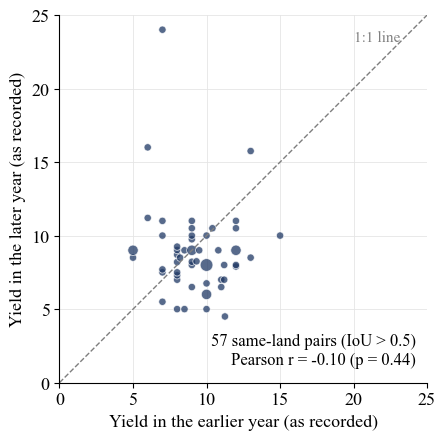

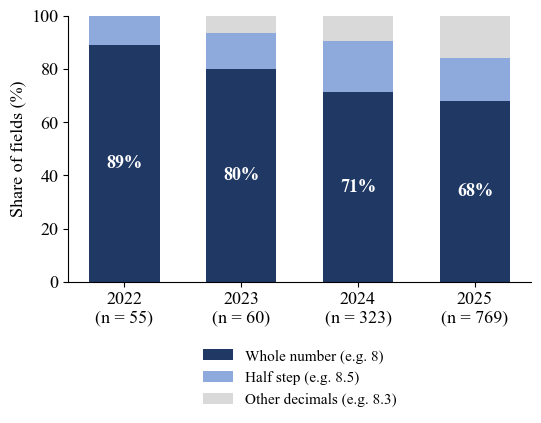

saved to: f:\THESIS\mtech_thesis_crop_yield_estimation\reports\figures\phase1a


In [12]:
import matplotlib.pyplot as plt

FIG = ROOT / "reports" / "figures" / "phase1a"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# (a) same land in two years, dot size = number of pairs at that point
cnt = ok.groupby(["yield_a", "yield_b"]).size().reset_index(name="n")
lim = [0, max(ok["yield_a"].max(), ok["yield_b"].max()) + 1]
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot(lim, lim, ls="--", color="#7F7F7F", lw=1)
ax.text(lim[1] * 0.80, lim[1] * 0.93, "1:1 line", color="#7F7F7F", fontsize=11)
ax.scatter(cnt["yield_a"], cnt["yield_b"], s=28 * cnt["n"], color="#1F3864",
           alpha=0.75, edgecolor="white", lw=0.6)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("Yield in the earlier year (as recorded)")
ax.set_ylabel("Yield in the later year (as recorded)")
ax.text(0.97, 0.04, f"{len(ok)} same-land pairs (IoU > 0.5)\nPearson r = {r:.2f} (p = {p_r:.2f})",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=12)
ax.grid(color="#E5E5E5", lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "R1_same_land_yield.png", dpi=300, facecolor="white"); plt.show()

# (b) whole numbers, half steps and other decimals per year
fig, ax = plt.subplots(figsize=(5.6, 4.6))
x = range(len(yw))
ax.bar(x, yw["whole_number_pct"], 0.6, color="#1F3864", label="Whole number (e.g. 8)")
ax.bar(x, yw["half_step_pct"], 0.6, bottom=yw["whole_number_pct"], color="#8EA9DB", label="Half step (e.g. 8.5)")
ax.bar(x, yw["other_decimals_pct"], 0.6, bottom=yw["whole_number_pct"] + yw["half_step_pct"],
       color="#D9D9D9", label="Other decimals (e.g. 8.3)")
for i, v in enumerate(yw["whole_number_pct"]):
    ax.text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks(list(x), [f"{y}\n(n = {n})" for y, n in zip(yw["year"], yw["n"])])
ax.set_ylabel("Share of fields (%)"); ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False, fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "R1_yield_rounding.png", dpi=300, facecolor="white"); plt.show()

print("saved to:", FIG)

## Step 8: Map layers of the problems

Saves the R1 problems as point layers, so they can be shown on the Latur map in QGIS:
(1) same land in two years, (2) pairs in the same year that share a polygon,
(3) fields far from their taluka, (4) the "Jalkot" fields. One GeoPackage, EPSG:32643, no personal data.

**Found:** 57 same-land points, 8 shared-polygon points, 9 far fields and 7 "Jalkot" fields.

In [13]:
import geopandas as gpd

GPKG = OUT / "R1_problem_map.gpkg"
if GPKG.exists():
    GPKG.unlink()

# 1. Same land in two years: one point per pair, in the middle of the shared area
rows = []
for _, s in same.iterrows():
    shared = allf.geometry[s["rid_a"]].intersection(allf.geometry[s["rid_b"]])
    rows.append({"years": f"{s['year_a']}-{s['year_b']}", "iou": round(s["iou"], 2),
                 "yield_a": s["yield_a"], "yield_b": s["yield_b"],
                 "yield_diff": abs(s["yield_a"] - s["yield_b"]),
                 "geometry": shared.representative_point()})
same_pts = gpd.GeoDataFrame(rows, crs=allf.crs)

# 2. Pairs in the same year that share a polygon (IoU > 0.5)
rows = []
for y in pairs_df["year"].unique():
    g = raw[y][raw[y].geometry.notna()].to_crs(32643)
    g["geometry"] = g.geometry.make_valid()
    g = g.set_index("UID")
    for _, s in pairs_df[pairs_df["year"] == y].iterrows():
        both = g.geometry[s["uid_a"]].union(g.geometry[s["uid_b"]])
        rows.append({"year": y, "iou": s["iou"], "geometry": both.representative_point()})
shared_pts = gpd.GeoDataFrame(rows, crs=32643)

# 3. Fields far from the rest of their taluka, and 4. the "Jalkot" fields
def as_points(d):
    return gpd.GeoDataFrame(d[["year", "Taluka", "km_from_taluka_centre"]].round(1),
                            geometry=gpd.points_from_xy(d["x"], d["y"]), crs=32643)
far_pts = as_points(loc[loc["far_from_taluka"]])
jalkot_pts = as_points(loc[loc["Taluka"] == "Jalkot"])

# save as layers of one GeoPackage (EPSG:32643, same as the QGIS project); no personal data
for name, layer in [("same_land_pairs", same_pts), ("shared_polygons", shared_pts),
                    ("far_from_taluka", far_pts), ("jalkot_fields", jalkot_pts)]:
    layer.to_file(GPKG, layer=name, driver="GPKG")
    print(f"{name:<16} {len(layer):>3} points")
print("\nsaved:", GPKG)


same_land_pairs   57 points
shared_polygons    8 points
far_from_taluka    9 points
jalkot_fields      7 points

saved: f:\THESIS\mtech_thesis_crop_yield_estimation\results\phase1a\R1_problem_map.gpkg


## Step 9: Figure for the location check

Histogram of each field's distance from the middle of its taluka's fields, with the
outlier cut-off (Q3 + 3 IQR). Fields to the right of the line are the "far" fields.
This is a screening step; R3 checks every field against the real taluka boundaries.

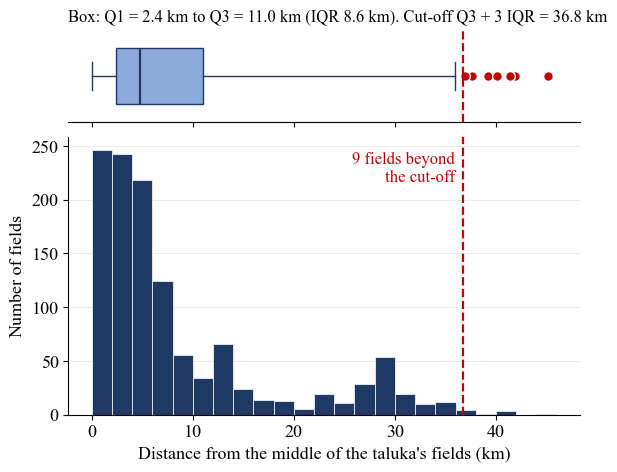

Q1 2.4 km | Q3 11.0 km | IQR 8.6 km | cut-off 36.8 km | far fields 9 of 1206


In [14]:
import matplotlib.pyplot as plt

FIG = ROOT / "reports" / "figures" / "phase1a"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

d = loc["km_from_taluka_centre"]
n_far = int((d > limit).sum())

fig, (axb, axh) = plt.subplots(2, 1, figsize=(6.6, 5.0), sharex=True,
                               gridspec_kw={"height_ratios": [1, 3], "hspace": 0.08})

# box plot: box = Q1 to Q3, whiskers reach to 3 IQR, dots beyond = far fields
axb.boxplot(d, vert=False, whis=3, widths=0.6, patch_artist=True,
            boxprops=dict(facecolor="#8EA9DB", edgecolor="#1F3864"),
            medianprops=dict(color="#1F3864", lw=1.6),
            whiskerprops=dict(color="#1F3864"), capprops=dict(color="#1F3864"),
            flierprops=dict(marker="o", markerfacecolor="#C00000", markeredgecolor="white", markersize=7))
axb.axvline(limit, color="#C00000", lw=1.6, ls="--")
axb.set_yticks([]); axb.spines["left"].set_visible(False)
axb.set_title(f"Box: Q1 = {q1:.1f} km to Q3 = {q3:.1f} km (IQR {q3 - q1:.1f} km). "
              f"Cut-off Q3 + 3 IQR = {limit:.1f} km", fontsize=12, loc="left")

# histogram: the full shape of the distances
axh.hist(d, bins=range(0, int(d.max()) + 3, 2), color="#1F3864", edgecolor="white", lw=0.5)
axh.axvline(limit, color="#C00000", lw=1.6, ls="--")
axh.text(limit - 0.8, axh.get_ylim()[1] * 0.95, f"{n_far} fields beyond\nthe cut-off",
         color="#C00000", fontsize=12, ha="right", va="top")
axh.set_xlabel("Distance from the middle of the taluka's fields (km)")
axh.set_ylabel("Number of fields")
axh.grid(axis="y", color="#E5E5E5", lw=0.6); axh.set_axisbelow(True)

fig.savefig(FIG / "R1_taluka_distance.png", dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
print(f"Q1 {q1:.1f} km | Q3 {q3:.1f} km | IQR {q3 - q1:.1f} km | cut-off {limit:.1f} km | far fields {n_far} of {len(d)}")

## Summary of R1

**Problems found (fixed in R2 to R4):**
1. 2022 to 2024 are two survey batches merged together, with different column names.
2. Harvest dates are partly swapped (day and month). 17 sowing dates and 3 harvest dates have the wrong year.
3. 34 fields have a yield but no sowing date, variety or actual area.
4. `Area_acres` and `PolyArea` are just calculated polygon areas (7 negative in 2025).
   The farmer-reported areas differ from the polygon by more than 20% for many fields.
5. 8 pairs of fields in 2025 share (almost) the same polygon but belong to different farmers (16 fields).
6. 6 multi-part fields (3 real splits, 3 with tiny slivers); 2 broken polygons and 1 missing polygon (2025).
7. 73 variety spellings, including junk values.
8. Real soil lab values for only 232 of 1,207 fields.
9. 9 fields far from their taluka; the 7 "Jalkot" fields have the wrong taluka.
10. 64 farmers have more than one field in a year. Their fields must stay together
    when splitting into training and test data.

**Evidence that the yield labels are noisy:**
- The same land in two years shows no relation in yield (r = -0.10, n = 57).
- Most yields are whole numbers (68 to 89%).

**Open points we'll check ourselves from the data:**
1. Yield unit (per acre or per hectare): compare with official Latur soybean yields (Phase 1B).
2. The "same plot" overlap cut-off: the histogram has no clean gap, so test a few cut-offs in R3.
3. Units of the soil values: compare with typical soil test ranges (R4).
4. Shared polygons: decide using their yields and dates (R3).